# Automobile: linear vs quadratic regression (small regression dataset)

**Data:** UCI *Automobile* (imports-85), 205 cars, 25 features (sizes, engine, make, ...).
**Target:** `price`. **Metric:** mean squared error (MSE).

Steps of the lab covered here:
1. learning curves for **linear regression** (train and validation MSE vs. training-set size)
2. the same for **quadratic regression**
3. **cross-validation** to choose between the two, compared with 1. and 2.

The code lives in `lab/`: the loader `lab/data_automobile.py`, the models `lab/models.py`,
the experiment loop `lab/experiment.py` and the plots `lab/plotting.py`.

In [1]:
import sys
sys.path.append("..")  # make the lab/ package (one folder up) importable

import pandas as pd
from IPython.display import display

from lab import FIGURES_DIR, RESULTS_DIR
from lab.experiment import baseline_score, cross_validate_models, run_learning_curve, summarize
from lab.models import make_model
from lab.plotting import plot_learning_curve

# TODO: replace with Jakob's sampler once it exists:
#   from lab.sampler import linear_sizes, log_sizes, sample_training_sets
from lab.temp_prep import linear_sizes, log_sizes, sample_training_sets

RESULTS_DIR.mkdir(exist_ok=True)
pd.set_option("display.float_format", "{:.4g}".format)

In [2]:
DATASET = "automobile"
TASK = "regression"
KINDS = ["linear", "quadratic"]
N_REPEATS = 10   # how many different random samples per training-set size

## Load the data
The loader reads `?` as missing, drops the 4 cars without a price and turns the word
columns `num-of-doors` / `num-of-cylinders` into numbers. Remaining missing values are
filled in by the model pipeline (median / most frequent value of the *training sample*).

In [3]:
from lab.data_automobile import load_automobile

X, y = load_automobile()
print(X.shape)
display(X.head())
print("missing values per column:")
print(X.isna().sum()[X.isna().sum() > 0])

(201, 25)


,symboling,normalized-losses,make,fuel-type,aspiration,num-of-doors,body-style,drive-wheels,engine-location,wheel-base,...,num-of-cylinders,engine-size,fuel-system,bore,stroke,compression-ratio,horsepower,peak-rpm,city-mpg,highway-mpg
0,3,NaN,alfa-romero,gas,std,2,convertible,rwd,front,88.6,...,4,130,mpfi,3.47,2.68,9,111,5000,21,27
1,3,NaN,alfa-romero,gas,std,2,convertible,rwd,front,88.6,...,4,130,mpfi,3.47,2.68,9,111,5000,21,27
2,1,NaN,alfa-romero,gas,std,2,hatchback,rwd,front,94.5,...,6,152,mpfi,2.68,3.47,9,154,5000,19,26
3,2,164,audi,gas,std,4,sedan,fwd,front,99.8,...,4,109,mpfi,3.19,3.4,10,102,5500,24,30
4,2,164,audi,gas,std,4,sedan,4wd,front,99.4,...,5,136,mpfi,3.19,3.4,8,115,5500,18,22


missing values per column:
normalized-losses    37
num-of-doors          2
bore                  4
stroke                4
horsepower            2
peak-rpm              2
dtype: int64


## Train / validation split
20% of the cars are set aside as the validation set. They are never used for fitting,
only for measuring the error.

**How we split:** randomly, but **stratified on price** (`split_automobile` in
`lab/data_automobile.py`). Prices are skewed: most cars cost $7-17k, a handful
(Mercedes, BMW, Jaguar, Porsche) $30-45k. MSE squares the errors, so with only ~40
validation cars the result would depend a lot on how many expensive cars land there.
Cutting the prices into 5 equally full bins and stratifying on them gives training and
validation the same price range.

One caveat for the report: the catalog lists several trims of the same car model
(almost identical rows). A random split can put trims of one model on both sides, which
makes the validation error slightly optimistic. Grouping by model would avoid this but
would measure something else (performance on car models never seen before).

In [4]:
from lab.data_automobile import split_automobile

X_train, X_val, y_train, y_val = split_automobile(X, y)
print(f"training part: {len(X_train)} rows, validation: {len(X_val)} rows")
display(pd.DataFrame({"train": y_train.describe(), "validation": y_val.describe()}).round(0))

training part: 160 rows, validation: 41 rows


,train,validation
count,160,41
mean,1.329e+04,1.288e+04
std,8062,7567
min,5118,5348
25%,7785,7609
50%,1.047e+04,9298
75%,1.651e+04,1.558e+04
max,4.54e+04,3.418e+04


In [5]:
# How many features does each model actually see? (after one-hot / squaring)
# Compare these numbers with the training-set sizes on the x-axis below.
for kind in KINDS:
    prep = make_model(kind).named_steps["prep"].fit(X_train)
    print(f"{kind:>20}: {prep.transform(X_train.iloc[:5]).shape[1]} features")

              linear: 67 features
           quadratic: 220 features


Note that the number of features `p` is **larger than** most (linear) or all (quadratic)
of our training-set sizes `n`. This explains a lot of the curves below. Only numeric
columns are squared for the quadratic model; see the docstring of `lab/models.py` for why.

## Steps 1 & 2: learning curves

In [6]:
# Training-set sizes 10, 20, ..., up to the whole training part.
sizes = linear_sizes(10, len(X_train), 10)
if sizes[-1] != len(X_train):
    sizes.append(len(X_train))
print(sizes)

samples = sample_training_sets(y_train, sizes, N_REPEATS, TASK)
curve = run_learning_curve(X_train, y_train, X_val, y_val, KINDS, samples, TASK, verbose=False)
curve.to_csv(RESULTS_DIR / f"{DATASET}_curve.csv", index=False)

stats = summarize(curve)
display(stats)

[10, 20, 30, 40, 50, 60, 70, 80, 90, 100, 110, 120, 130, 140, 150, 160]


model size train_score                                          \
                          mean       std    median       q25       q75   
0      linear   10   8.979e-23 6.501e-23 7.312e-23 4.465e-23 1.332e-22   
1      linear   20    7.75e-22 1.623e-21 1.468e-22 1.129e-22 4.805e-22   
2      linear   30       604.7      1912 1.763e-22 9.053e-23 2.123e-22   
3      linear   40    2.27e+04 4.526e+04       785  3.35e-22 2.982e+04   
4      linear   50   7.995e+04 8.877e+04 6.907e+04      4997 1.203e+05   
5      linear   60    3.49e+05 1.772e+05 3.438e+05 1.963e+05 4.934e+05   
6      linear   70   6.999e+05 2.807e+05  5.55e+05 5.145e+05 8.957e+05   
7      linear   80   8.198e+05 4.485e+05 6.189e+05 5.474e+05 8.791e+05   
8      linear   90   1.516e+06 4.694e+05 1.521e+06 1.163e+06 1.724e+06   
9      linear  100   1.365e+06  3.79e+05 1.261e+06 1.167e+06 1.517e+06   
10     linear  110   1.776e+06 3.216e+05   1.8e+06 1.574e+06 1.902e+06   
11     linear  120   1.736e+06 3.162e+05 1.751e+06 1.593e+06  1.95e+06   
12     linear  130   1.762e+06 3.926e+05 1.795e+06 1.569e+06 1.933e+06   
13     linear  140   1.989e+06 3.776e+05 2.167e+06  1.79e+06 2.204e+06   
14     linear  150    2.23e+06 2.049e+05  2.31e+06 2.148e+06 2.385e+06   
15     linear  160   2.324e+06         0 2.324e+06 2.324e+06 2.324e+06   
16  quadratic   10   7.827e-23  6.07e-23 7.097e-23 4.479e-23 9.049e-23   
17  quadratic   20   4.442e-22  9.87e-22 1.021e-22 7.986e-23 1.758e-22   
18  quadratic   30   1.299e-22 6.813e-23 1.215e-22   7.8e-23 1.603e-22   
19  quadratic   40        4841 1.217e+04 3.145e-22 1.469e-22 5.175e-21   
20  quadratic   50        4975      9874 8.033e-21 5.557e-22      6075   
21  quadratic   60        9250 1.168e+04      3375  7.61e-22 2.144e+04   
22  quadratic   70        9086 1.274e+04      2893 1.469e-19 1.785e+04   
23  quadratic   80        4305      6030      2531 8.302e-20      6434   
24  quadratic   90        6590      7646      5312 1.277e-18      9500   
25  quadratic  100        7256      8589      4781      4050      5513   
26  quadratic  110        8912      7342      5847      4014 1.428e+04   
27  quadratic  120   1.459e+04      6210 1.674e+04 1.232e+04 1.848e+04   
28  quadratic  130   1.752e+04      5817 1.839e+04 1.626e+04 2.021e+04   
29  quadratic  140   1.936e+04      5186  1.98e+04 1.823e+04 2.297e+04   
30  quadratic  150   2.026e+04      4229 2.172e+04 1.921e+04 2.255e+04   
31  quadratic  160     2.3e+04         0   2.3e+04   2.3e+04   2.3e+04   

   val_score                                          
        mean       std    median       q25       q75  
0  4.376e+07 4.196e+07 3.068e+07 2.376e+07 4.661e+07  
1  2.681e+08 6.299e+08 2.453e+07  1.93e+07 3.526e+07  
2  6.539e+07 9.775e+07 3.237e+07 1.897e+07 5.456e+07  
3  1.743e+08 2.449e+08 7.296e+07 3.923e+07 1.299e+08  
4  1.632e+09 3.413e+09 4.472e+08 1.575e+08 1.164e+09  
5  5.126e+07 3.483e+07 3.904e+07 3.188e+07 5.557e+07  
6  6.777e+07 9.768e+07 3.331e+07 1.523e+07 3.918e+07  
7  2.585e+07 1.382e+07 2.466e+07 1.619e+07 3.636e+07  
8  1.469e+07 1.228e+07 1.007e+07 8.876e+06 1.431e+07  
9  1.164e+07 7.472e+06 1.126e+07 4.547e+06 1.558e+07  
10 7.171e+06 4.058e+06 5.714e+06 4.212e+06 7.917e+06  
11 8.125e+06 6.827e+06  5.73e+06 4.283e+06 8.624e+06  
12 4.138e+06 1.119e+06 3.762e+06 3.539e+06 4.614e+06  
13 4.286e+06 6.668e+05 4.033e+06 3.882e+06 4.915e+06  
14 3.848e+06 3.647e+05 3.828e+06 3.593e+06 3.898e+06  
15 3.581e+06         0 3.581e+06 3.581e+06 3.581e+06  
16 4.793e+07 3.947e+07 3.223e+07 2.333e+07 5.076e+07  
17 4.469e+08 1.213e+09 2.653e+07 1.982e+07 3.875e+07  
18 4.399e+07 5.031e+07 2.104e+07 1.943e+07 4.171e+07  
19 4.701e+08 1.232e+09   2.3e+07 1.969e+07 1.294e+08  
20 9.392e+08 1.496e+09 9.105e+07 4.877e+07 1.417e+09  
21 3.106e+08 4.111e+08 1.346e+08 7.101e+07 3.205e+08  
22 1.716e+10  4.99e+10 6.273e+08 1.588e+08 2.194e+09  
23 6.408e+09 1.411e+10 1.646e+09 6.818e+08  3.62e+09  
24  1.58e+10 2.296e+10 2.343e+09 1.158e+09 3.445e+10  
25 4.3

baseline validation MSE: 5.604e+07  (RMSE $7,486)


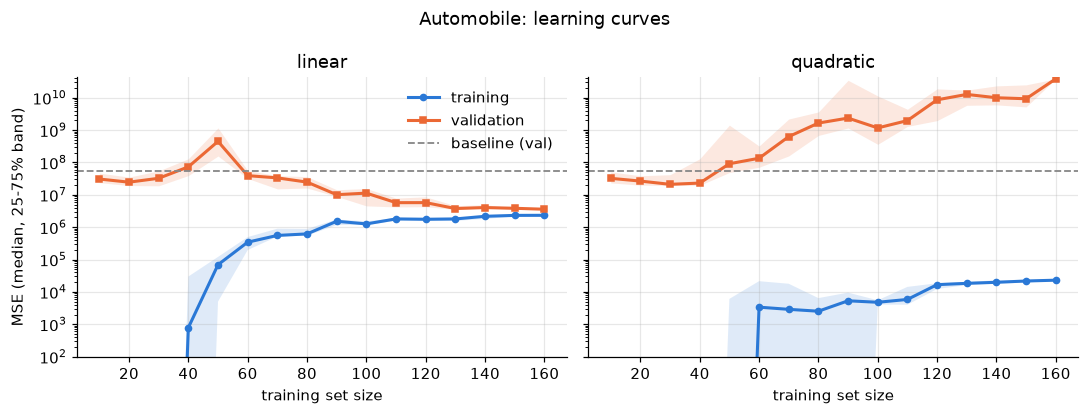

In [7]:
# Reference: always predict the mean price of the training part.
baseline = baseline_score(X_train, y_train, X_val, y_val, TASK)
print(f"baseline validation MSE: {baseline:.4g}  (RMSE ${baseline ** 0.5:,.0f})")

# Training MSE is exactly 0 for the smallest samples, which a log axis cannot show;
# ylim cuts the axis at 100 so those points simply drop off the bottom.
fig = plot_learning_curve(curve, "MSE", "Automobile: learning curves", baseline=baseline,
                          log_y=True, ylim=(1e2, None),
                          path=FIGURES_DIR / f"{DATASET}_learning_curves.png")

### What the curves show (step 1d)

**Training error (blue).** For small samples the training MSE is (numerically) **zero**:
when there are at least as many features as data points, least squares can pass the
fitted function exactly through every training point. Once `n` exceeds the number of
*effectively independent* features, this is no longer possible and the training MSE
rises, levelling off at the error the model cannot avoid (noise + what a linear function
cannot express). The effective number is smaller than the printed feature count:
one-hot columns of makes that are not in the sample are all zero, and some columns are
nearly copies of each other (e.g. `city-mpg` / `highway-mpg`).

**Validation error (orange).** With few points the model learns noise, so the
validation MSE is high, about as bad as always predicting the average price (the
baseline). It is **largest around
`n ≈ p`**: there the model is forced to fit every point exactly with a nearly singular
system, which needs huge coefficients that generalize badly (the peak of the so-called
*double descent* curve). With more data than features the validation MSE falls and
moves towards the training MSE. The gap between the two curves is the overfitting
(variance); where they would meet is the bias + noise level.

**Linear vs quadratic.** The quadratic model has more features than our whole
training part, so it never leaves the "too few data points" regime: its training MSE
stays tiny and its validation MSE gets *worse* as `n` approaches `p` (we only see the
left side of the double-descent peak). With ~160 cars there is simply not enough data to
estimate ~220 coefficients without regularization.

**Variability.** The shaded band (25-75% of the repeated samples) is wide for small `n`:
which cars end up in a sample matters a lot. At the largest size every repeat uses the
whole training part, so the band disappears.

## Step 3: cross-validation
5-fold CV on the training part only (the validation set stays untouched). Each fold
trains on 4/5 of the training part (~128 cars) and is scored on the remaining 1/5.

In [8]:
cv = cross_validate_models(X_train, y_train, KINDS, TASK, k=5)
cv.to_csv(RESULTS_DIR / f"{DATASET}_cv.csv", index=False)

# Put the CV estimate next to the learning-curve values at the largest size.
largest = stats[stats["size"] == stats["size"].max()]
curve_end = pd.DataFrame({
    "model": largest["model"],
    "curve_train": largest[("train_score", "median")],
    "curve_val": largest[("val_score", "median")],
})
comparison = cv.merge(curve_end, on="model")
display(comparison)
print("CV chooses:", cv.loc[cv["cv_mean"].idxmin(), "model"])

,model,cv_mean,cv_std,n_rows,curve_train,curve_val
0,linear,1.528e+07,1.212e+07,160,2.324e+06,3.581e+06
1,quadratic,1.084e+10,1.115e+10,160,2.3e+04,3.815e+10


CV chooses: linear


### CV vs. the learning curves (step 3)

CV clearly prefers the **linear** model, in agreement with the validation curves.

- The CV error is far above the **training** error at full size: the training error is
  measured on the very points the model was fitted to, so it is optimistic.
- Both the CV error and the **validation** error measure performance on unseen cars, but
  they need not be equal. With only ~40 cars per held-out set, the error depends a lot on
  *which* cars are held out: compare `cv_std` with `cv_mean`, the folds differ by a large
  factor, mostly depending on how many expensive cars they contain. Our single validation
  set is one such draw (it happens to have no car above ~$34k). CV averages over 5 draws,
  so it is the more reliable estimate. Also, each CV model is trained on ~128 instead of
  ~160 cars, i.e. CV corresponds to a point a bit to the left on the learning curve.
- For the quadratic model the CV error is huge and varies a lot between folds, which is
  exactly the unstable p > n behaviour seen in the curves.